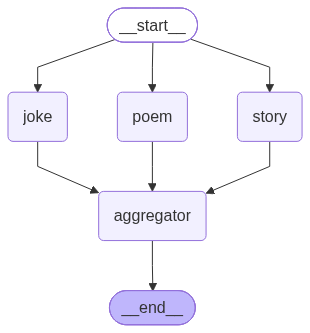

Here's a story, joke, and poem about 程序员!

STORY:
林墨的指尖停在键盘上方，屏幕上的代码像一片没有星光的夜空。凌晨三点，办公室只剩下主机风扇的低鸣，像某种机械的呼吸。他正在改写一段十年前的遗留代码，那些用早已失传的框架写成的逻辑，像一座坍塌了一半的迷宫。

没人记得这段代码是谁写的，git记录显示最初的提交者账号已经注销，注释里只有一句中文：“此处有龙，勿动。”但林墨必须动它——系统每天在凌晨三点零七分崩溃，像被精确计算过的诅咒。

他调出崩溃前最后一次日志。在无数错误堆栈的缝隙里，他看见一行不该存在的输出：

```c
printf("你找到我了。");
```

林墨的手从键盘上缩回来。这段代码不该执行到这个位置——它在昨天就被他注释掉了。

第二夜，他重新整理调用栈。在递归的最深处，一个变量名引起了他的注意：`hello_world_forever`。点开定义，里面是一串看似随机的数字，但林墨立刻认出那是ASCII码。转译过来是：“你好，我是林深。”

林深。他失踪多年的哥哥。

十年前，林深也是程序员。他消失的那天，只留下一张纸条：“我去找代码的尽头了。”监控显示他走进机房，再没出来。

林墨开始逐行比对。他发现每当系统崩溃，这个变量就会被激活一次，像某种心跳。他试着修改它，但编译器报错：`变量受保护，来源：未知`。

第三夜，他写了一个脚本，模拟崩溃前的每一个操作。凌晨三点零七分，屏幕突然亮起，不再是代码，而是一段视频。画面里是机房，2014年的机房，林深坐在镜头前，背后的服务器嗡嗡作响。

“如果你看到这个，”视频里的林深说，“说明你终于读到了这一层。我把自己写进了系统，用递归函数模拟意识。每一天的崩溃，其实是我在试图往外爬。但每次重置都会让我忘掉一些东西。这个视频是我留下来提醒自己的。”

视频结束，屏幕回到代码界面。林墨发现光标自己动了。它在空白处打出一行字：

```c
while(true) { 林墨 := 林深; }
```

林墨深吸一口气。他终于明白哥哥说的“代码的尽头”是什么意思——那是一个无限循环，一个把自己作为参数的递归调用。每一次迭代，他都更接近林深，又更远离林深。

他写下一行代码，作为回应：

```c
if 林墨 = 林深 { break; }
```

系统沉默了整整一分钟。然

In [1]:
from typing import Annotated, TypedDict, Literal, List
from langgraph.graph import StateGraph, START, END
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from IPython.display import Image, display
from operator import add
from dotenv import load_dotenv

load_dotenv()

def display_graph(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))

llm = init_chat_model("deepseek-chat")
# Graph state
class State(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str

# Nodes
def joke_node(state: State):
    """First LLM call to generate initial joke"""

    msg = llm.invoke(f"Write a joke about {state['topic']}")
    return {"joke": msg.content}

def story_node(state: State):
    """Second LLM call to generate story"""

    msg = llm.invoke(f"Write a short story about {state['topic']}")
    return {"story": msg.content}

def poem_node(state: State):
    """Third LLM call to generate poem"""

    msg = llm.invoke(f"Write a short poem about {state['topic']}")
    return {"poem": msg.content}


def aggregator(state: State):
    """Combine the joke, story and poem into a single output"""

    combined = f"Here's a story, joke, and poem about {state['topic']}!\n\n"
    combined += f"STORY:\n{state['story']}\n\n"
    combined += f"JOKE:\n{state['joke']}\n\n"
    combined += f"POEM:\n{state['poem']}"
    return {"combined_output": combined}


# Build workflow
parallel_builder = StateGraph(State)

# Add nodes
parallel_builder.add_node("joke", joke_node)
parallel_builder.add_node("story", story_node)
parallel_builder.add_node("poem", poem_node)
parallel_builder.add_node("aggregator", aggregator)

# Add edges to connect nodes
parallel_builder.add_edge(START, "joke")
parallel_builder.add_edge(START, "story")
parallel_builder.add_edge(START, "poem")
parallel_builder.add_edge("joke", "aggregator")
parallel_builder.add_edge("story", "aggregator")
parallel_builder.add_edge("poem", "aggregator")
parallel_builder.add_edge("aggregator", END)
parallel_workflow = parallel_builder.compile()

# Show workflow
display_graph(parallel_workflow)
# Invoke
state = parallel_workflow.invoke({"topic": "程序员"})
print(state["combined_output"])